# Linear and Quadratic discriminant Analysis 
En esta practica estudiamos dos metodos de aprendizaje supervizado (LDA y QDA). 
Estos son metodos basados en la informacion estadistica de cada clase para realizar predicciones.

Al igual que en otras practicas trabajaremos con datos hechos con `make blobs` para poder analizar los algoritmos.

Ambos algoritmos nacen de la idea de que nuestras clases se distribuyen de forma gaussina. Usando probabilidad bayesiana podemos llegar a dos formulas: 

* Si todas las clases comparten la misma covarianza entonces llegamos a una ecuacion lineal y solo basta evaluar en cada recta y encontrar la que devuelve el valor mayor.

* Si cada clase tiene si propia covarianza entonces llegamos a una forma cuadratica y al igual, basta encontrar donde tengamos el mayor valor.

In [121]:
import numpy as np 
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generacion de datos
Generamos 700 datos con 3 centroides. La idea es que se noten la distincion de las clases pero que tambien sean confusas, para que el algoritmo no tenga una prueba sencilla.

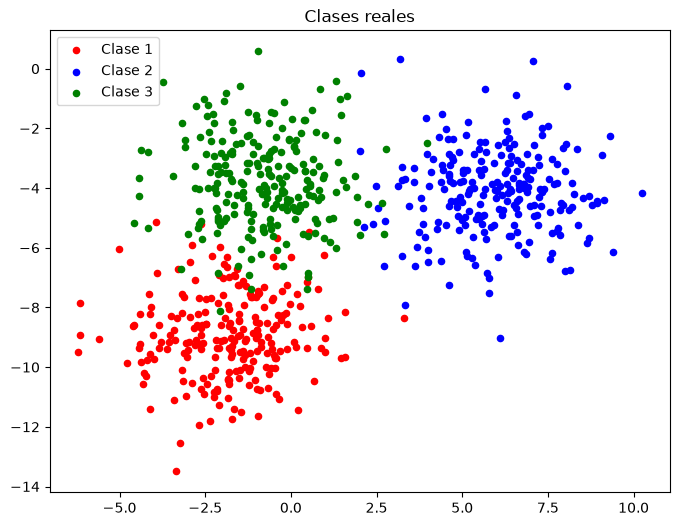

In [78]:
## Generación y exploración de datos 
X, y = make_blobs(n_samples=700, centers=3,  n_features=2, cluster_std=1.5, random_state=40)
#visualizacion
colores = ['red', 'blue', 'green']
clases = ['Clase 1', 'Clase 2', 'Clase 3']

plt.figure(figsize=(8, 6))

plt.title('Clases reales')

for clase_id in np.unique(y):
    #solo los puntos que pertenecen a esta clase
    mascara = (y == clase_id)
    plt.scatter(X[mascara, 0], X[mascara, 1], color=colores[clase_id], label=clases[clase_id], s=20)

plt.legend()
plt.show()

# Separación de datos

Se ocupan 560 datos para entrenamiento
Se ocupan 140 datos para evaluar 


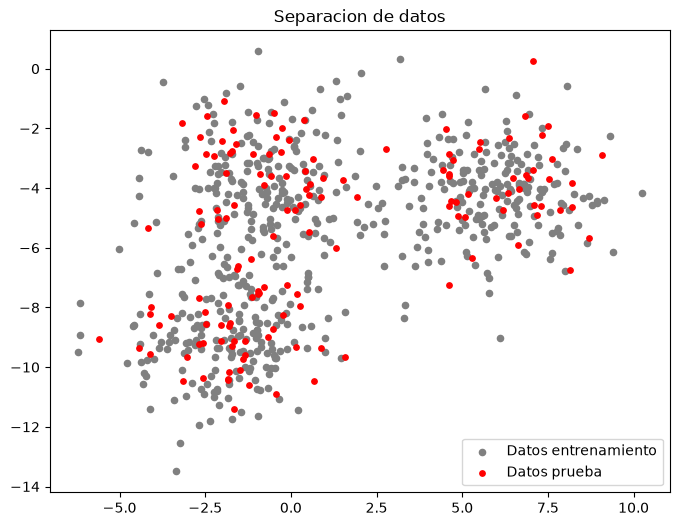

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Se ocupan {len(X_train)} datos para entrenamiento')
print(f'Se ocupan {len(X_test)} datos para evaluar ')

plt.figure(figsize=(8, 6))
plt.title('Separacion de datos')
plt.scatter(X_train[:, 0], X_train[:, 1], color = 'gray', label = 'Datos entrenamiento', s=20)
plt.scatter(X_test[:, 0], X_test[:, 1], color = 'red', label = 'Datos prueba', s=15)
plt.legend()
plt.show()

# LDA
Vamos a probar los datos anteriores en el algoritmo que construí para hacer LDA. La estructura del codigo sigue la logica matematica y solo es implementada a codigo.

In [80]:
class LDA:
    def __init__(self):
        self.X = None
        self.y = None
        self.pesos = None 
        self.covarianza = None
        self.centroides = None
        self.clases = None

    def fit(self, X, y):
        self.X = np.array(X)
        self.y = np.array(y)

        N = len(self.y) #total de datos
        clases, contadores = np.unique(self.y, return_counts=True)  #cuantos elementos tiene cada clase
        
        K = len(clases)
        PI = contadores / N

        #encontramos los puntos en cada clase y obtenemos la media (centroides)
        centroides = np.zeros((len(PI), self.X.shape[1]))
        for i, id in enumerate(clases):
            mascara = y == id
            centroides[i] = np.mean(self.X[mascara], axis = 0)

        #covarianzas 
        #primero obtenemos la covarianza de cada gaussiana 
        matriz_suma_total = np.zeros((self.X.shape[1], self.X.shape[1]))
        for i, clase in enumerate(clases):
            #vectores de la clase
            mascara = y == clase
            vec = self.X[mascara] 

            #calculamos la multiplicacion de cada vector y al final sumamos las matrices
            trans = []
            for v in vec:
                mul = np.outer( v-centroides[i], v-centroides[i])  #calcula la multiplicacion de un vector x x^t
                trans.append(mul)
            suma_clase = np.sum(trans, axis = 0)

            matriz_suma_total += suma_clase

        covarianza_agrupada = matriz_suma_total / (N - K)

        self.pesos = PI
        self.centroides = centroides 
        self.covarianza = covarianza_agrupada
        self.clases = clases

        return self 
    
    def predict(self, x):
        '''
        Predice el valor de un nuevo punto.
        Solo funciona para un punto, no para vectores de puntos.
        '''
        scores = np.zeros(len(self.centroides))

        inv = np.linalg.inv(self.covarianza)  #inversa compartida
        # a cada clase obtenemos la recta evaluada en x y finalmente devolvemos la mayor
        for i in range(len(scores)):
            m = self.centroides[i]
            Wk = (inv @ m).T
            Wko = -0.5 * (m @ (inv @ m)) + np.log(self.pesos[i])
            scores[i] = Wk @ x + Wko 

        indice = np.argmax(scores)

        return self.clases[indice]


### Entrenamiento y predicciones para LDA

In [89]:
lda = LDA()
lda.fit(X_train, y_train)
predicciones_lda = np.array([lda.predict(x_i) for x_i in X_test])


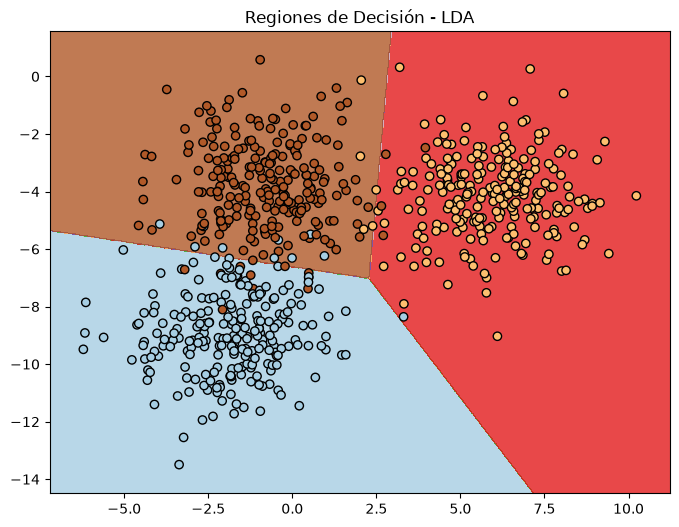

In [82]:
#region de visualizacion
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

puntos = np.c_[xx.ravel(), yy.ravel()]

predicciones = np.zeros(puntos.shape[0])
for i in range(puntos.shape[0]):
    predicciones[i] = lda.predict(puntos[i])


Z = predicciones.reshape(xx.shape)

# graficación de las fronteras de decisión
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.Paired)
plt.title("Regiones de Decisión - LDA")
plt.show()

Accuracy:  0.9714
Precision: 0.9717
Recall:    0.9731
F1 Score:  0.9723


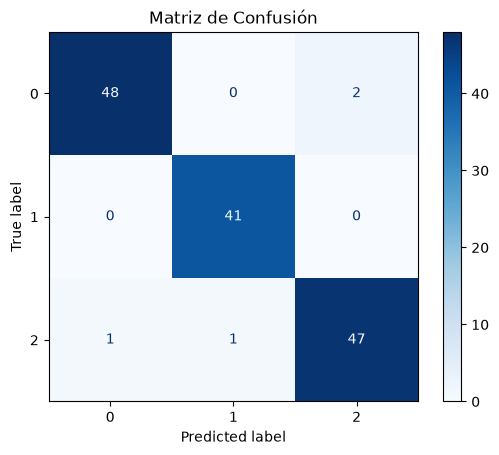

In [91]:
acc = accuracy_score(y_test, predicciones_lda)
prec = precision_score(y_test, predicciones_lda, average='macro') # Usar 'macro' o 'weighted' si hay >2 clases
rec = recall_score(y_test, predicciones_lda, average='macro')
f1 = f1_score(y_test, predicciones_lda, average='macro')

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")

cm = confusion_matrix(y_test, predicciones_lda)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lda.clases)
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.show()

Suponer que las clases comparten la misma matriz de covarianza hace que la region final sobre la que encontramos los valores sea una funcion lineal (por ellos las regiones estan divididas por rectas). 
Podemos notar que la clase 1 fue la que clasificó correctamente aunque las demas clases solo hubo errores pequeños (pocos valores mal clasificados) y podemos notarlo en nuestra matriz de confusión.

# QDA
Al igual que con LDA, vamos a probar el codigo que construí (que es muy parecido a LDA).

In [83]:

class QDA:
    def __init__(self):
        self.X = None
        self.y = None
        self.pesos = None
        self.centroides = None
        self.covarianzas = None
        self.clases = None


    def fit(self, X, y):
        self.X = np.array(X)
        self.y = np.array(y)

        N = len(self.y) #total de datos
        clases, contadores = np.unique(self.y, return_counts=True)  #cuantos elementos tiene cada clase
        
        PI = contadores / N

        #encontramos los puntos en cada clase y obtenemos la media (centroides)
        centroides = np.zeros((len(PI), self.X.shape[1]))
        for i, id in enumerate(clases):
            mascara = y == id
            centroides[i] = np.mean(self.X[mascara], axis = 0)


        #calculamos la covarianza de cada clase 
        covarianzas = []
        for i, clase in enumerate(clases):
            #vectores de la clase
            mascara = y == clase
            vec = self.X[mascara] 

            #calculamos la multiplicacion de cada vector y al final sumamos las matrices
            trans = []
            for v in vec:
                mul = np.outer( v-centroides[i], v-centroides[i])  #calcula la multiplicacion de un vector x x^t
                trans.append(mul)
            suma = np.sum(trans, axis = 0)

            #formula de cada covarianza 
            cov = ( 1 / (contadores[i] - 1 ) ) * (suma)
            covarianzas.append(cov)

        self.pesos = PI
        self.centroides = centroides
        self.covarianzas = covarianzas
        self.clases = clases 

        return self


    def predict(self, x):
        '''
        Predice el valor de un nuevo punto.
        Solo funciona para un punto, no para vectores de puntos.
        '''
        scores = np.zeros(len(self.centroides))

        for i in range(len(scores)):
            inv = np.linalg.inv(self.covarianzas[i])
            m = self.centroides[i]
            scores[i] = -0.5 * ((x-m) @ (inv @ (x-m))) -0.5*(np.log( np.linalg.det(self.covarianzas[i]) )) + np.log(self.pesos[i])

        indice = np.argmax(scores)
        
        return self.clases[indice]


### Entrenamiento y predicciones

In [100]:
qda = QDA()
qda.fit(X_train, y_train)
predicciones_qda= np.array([qda.predict(x_i) for x_i in X_test])

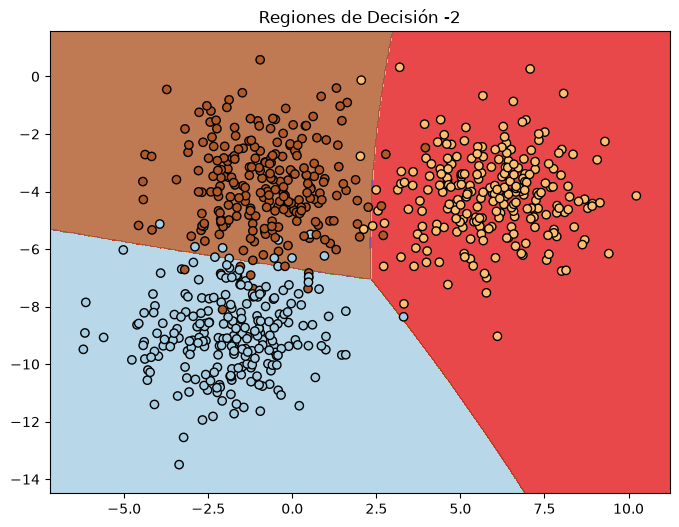

In [101]:
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

puntos = np.c_[xx.ravel(), yy.ravel()]

predicciones2 = np.zeros(puntos.shape[0])
for i in range(puntos.shape[0]):
    predicciones2[i] =qda.predict(puntos[i])

Z = predicciones2.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.Paired)
plt.title("Regiones de Decisión -2")
plt.show()

Accuracy:  0.9714
Precision: 0.9717
Recall:    0.9731
F1 Score:  0.9723


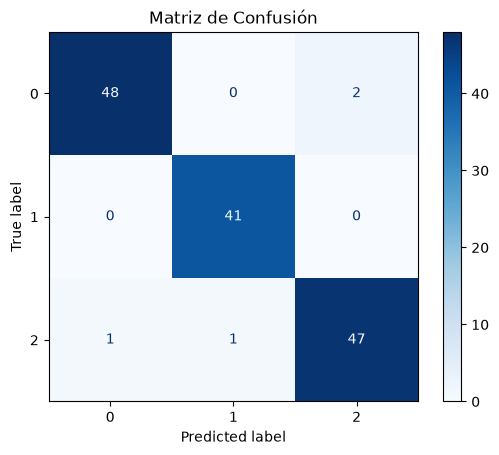

In [ ]:
acc1 = accuracy_score(y_test, predicciones_qda)
prec1 = precision_score(y_test, predicciones_qda, average='macro') 
rec1 = recall_score(y_test, predicciones_qda, average='macro')
f12 = f1_score(y_test, predicciones_qda, average='macro')

print(f"Accuracy:  {acc1:.4f}")
print(f"Precision: {prec1:.4f}")
print(f"Recall:    {rec1:.4f}")
print(f"F1 Score:  {f12:.4f}")

cm = confusion_matrix(y_test, predicciones_qda)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=qda.clases)
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.show()

Ahora con QDA nuestro algoritmo no se simplifica en evaluar una funcion lineal sino una funcion cuadratica y eso pasa porque las matrices de covarianza son distintas en cada clase (por ello las curvas de decision son de esa forma). 
Los dos algoritmos obtuvieron metricas muy parecidas aunque esto se debe por los datos de este ejemplo y puede variar con cada caso. 

## Moviendo la distribución de los datos 
Ahora moveremos la distribucion de nuestros datos para ver como se comportan los algoritmos. 

 El accuracy fue de 0.945
La precision fue de 0.9419254801595537


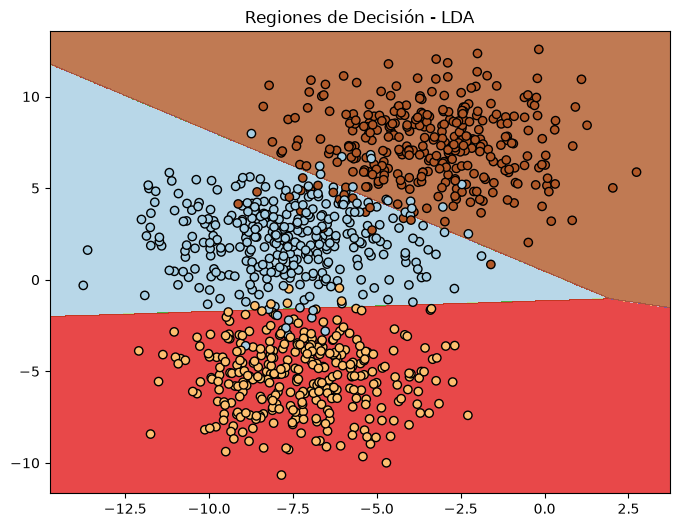

In [118]:
## Generación de nuevos datos 
X2, y2 = make_blobs(n_samples=1000, centers=3,  n_features=2, cluster_std=2, random_state=43)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2, random_state=42)

#aplicando los algoritmos 
lda2 = LDA()
lda2.fit(X_train2, y_train2)
predicciones_lda2 = np.array([lda2.predict(x_i) for x_i in X_test2])
acc3 = accuracy_score(y_test2, predicciones_lda2)
prec3 = precision_score(y_test2, predicciones_lda2, average='macro') 
print(f' El accuracy fue de {acc3}')
print(f'La precision fue de {prec3}')
#region de visualizacion
h = 0.02
x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

puntos = np.c_[xx.ravel(), yy.ravel()]

predicciones3 = np.zeros(puntos.shape[0])
for i in range(puntos.shape[0]):
    predicciones3[i] = lda2.predict(puntos[i])


Z = predicciones3.reshape(xx.shape)

# graficación de las fronteras de decisión
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X2[:, 0], X2[:, 1], c=y2, edgecolors='k', cmap=plt.cm.Paired)
plt.title("Regiones de Decisión - LDA")
plt.show()


El accuracy fue de 0.945
 La precision fue de 0.9419254801595537


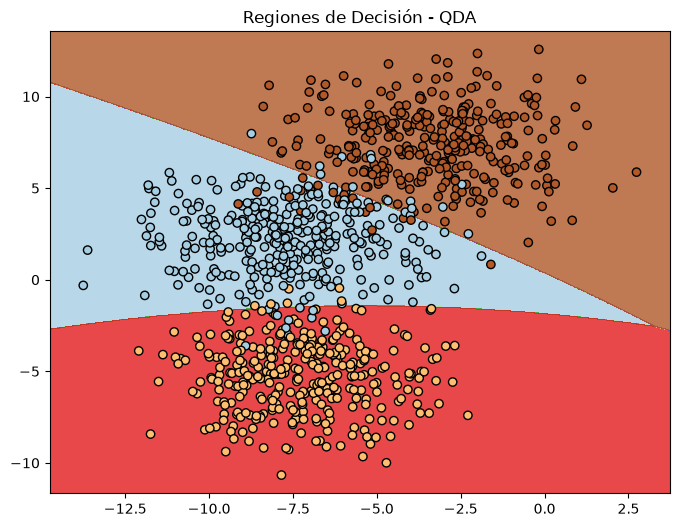

In [117]:
#aplicando QDA  
qda2 = QDA()
qda2.fit(X_train2, y_train2)

predicciones_qda2 = np.array([qda2.predict(x_i) for x_i in X_test2])
acc4 = accuracy_score(y_test2, predicciones_qda2)
prec4 = precision_score(y_test2, predicciones_qda2, average='macro') 
print(f'El accuracy fue de {acc4}')
print(f' La precision fue de {prec4}')

#region de visualizacion
h = 0.02
x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

puntos = np.c_[xx.ravel(), yy.ravel()]

predicciones4 = np.zeros(puntos.shape[0])
for i in range(puntos.shape[0]):
    predicciones4[i] = qda2.predict(puntos[i])


Z = predicciones4.reshape(xx.shape)

# graficación de las fronteras de decisión
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Paired)
plt.scatter(X2[:, 0], X2[:, 1], c=y2, edgecolors='k', cmap=plt.cm.Paired)
plt.title("Regiones de Decisión - QDA")
plt.show()


En este ejemplo si podemos notar más la diferencia en las fronteras, QDA si atrapa los datos de un forma más no tan rigida y permite formas más complejas. 
Dependiendo del problema nos conviene usar más un algoritmo u otro, si es que sabemos un poco sobre las formas de los datos. 